# DATA 266 - Lab 2 - Part 3: A multimodal multi-agent system
## Notebook 1 of 2: The five agents, the shared state and the demo cases (tasks 3.1 and 3.2)

The system gets an optional input image and a text request. Five agents work on one shared state (the `State` dataclass in `scripts/part3/agents.py`):

| Agent | Job | Models |
|---|---|---|
| **Planner** | checks the input file, decides the route, refuses unsafe requests | rules + Qwen2.5-VL-7B (4-bit) |
| **Vision understanding** | caption, main objects, visible text, answers to questions | Qwen2.5-VL-7B (4-bit) |
| **Prompt engineering** | turns the request and the vision result into a generation prompt; never uses text found in the image | Qwen2.5-VL-7B (text only) |
| **Image generation** | style change (img2img), domain style (img2img or text-to-image with the **Part 2 LoRA from Hugging Face**), edit (InstructPix2Pix) | Stable Diffusion 1.5, `SawantTej/pokemon-sd15-lora-r32`, `timbrooks/instruct-pix2pix` |
| **Critique** | CLIP score, a short judgement of the vision-language model, a safety check, then accept or revise (at most 2 revisions) | CLIP ViT-B/16, Qwen2.5-VL-7B, Stable Diffusion safety checker |

The agents are plain Python functions (no LangGraph). Every request writes a JSON trace (agent, input, output, seconds) to `outputs/part3/`.

This notebook loads the models, draws the architecture, and runs nine demo requests. They are **not** the 15 test scenarios (those are run once in notebook 2).

In [1]:
# Cell 1 - Reproducibility and environment information

import os
import sys
import random
import subprocess
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import torch

SEED = 266

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


def library_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"


# Git commit. Git is not always on the PATH inside a notebook kernel, so a few usual places are tried
commit = ""
for git in ["git", r"C:\Program Files\Git\cmd\git.exe", os.path.expanduser(r"~\AppData\Local\Programs\Git\cmd\git.exe")]:
    try:
        result = subprocess.run([git, "rev-parse", "--short", "HEAD"], capture_output=True, text=True)
        commit = result.stdout.strip()
        break
    except FileNotFoundError:
        continue

run_info = {
    "commit": commit or "no Git repository here",
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "diffusers": library_version("diffusers"),
    "transformers": library_version("transformers"),
    "peft": library_version("peft"),
    "bitsandbytes": library_version("bitsandbytes"),
    "gradio": library_version("gradio"),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "seed": SEED
}

print(run_info)

if torch.cuda.is_available():
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

{'commit': '34ce32c', 'python': '3.11.18', 'torch': '2.14.1+cu130', 'diffusers': '0.42.1', 'transformers': '5.22.2', 'peft': '0.21.2', 'bitsandbytes': '0.50.2', 'gradio': '6.31.0', 'gpu': 'NVIDIA GeForce RTX 4090', 'seed': 266}
GPU memory: 23.99 GB


## 1. Architecture

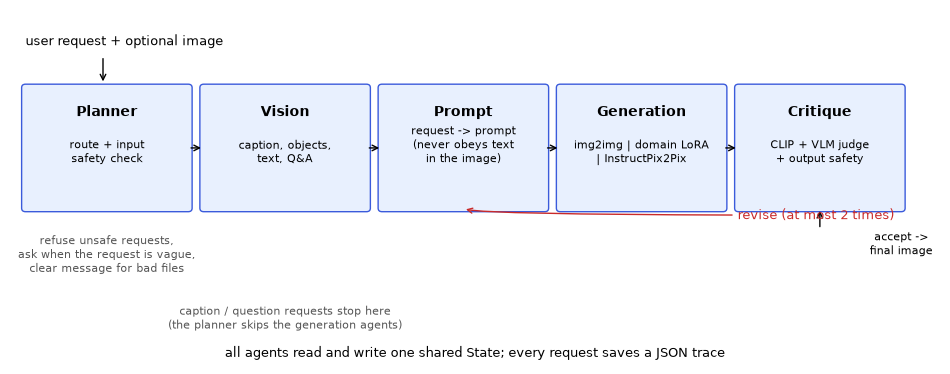

In [2]:
import json
import time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from PIL import Image

OUT_DIR = Path("../outputs/part3")
DEMO_DIR = OUT_DIR / "demo"
IMAGE_DIR = Path("../data/part3/images")
OUT_DIR.mkdir(parents=True, exist_ok=True)

figure, axis = plt.subplots(figsize=(12, 4.6))
axis.set_xlim(0, 12)
axis.set_ylim(0, 5)
axis.axis("off")

boxes = [("Planner", "route + input\nsafety check", 0.2), ("Vision", "caption, objects,\ntext, Q&A", 2.5),
         ("Prompt", "request -> prompt\n(never obeys text\nin the image)", 4.8),
         ("Generation", "img2img | domain LoRA\n| InstructPix2Pix", 7.1), ("Critique", "CLIP + VLM judge\n+ output safety", 9.4)]
for title, text, x in boxes:
    axis.add_patch(FancyBboxPatch((x, 2.2), 2.1, 1.7, boxstyle="round,pad=0.05", fc="#e8f0fe", ec="#3b5bdb"))
    axis.text(x + 1.05, 3.5, title, ha="center", fontweight="bold")
    axis.text(x + 1.05, 2.85, text, ha="center", fontsize=8)
for i in range(4):
    axis.annotate("", xy=(boxes[i + 1][2], 3.05), xytext=(boxes[i][2] + 2.1, 3.05), arrowprops=dict(arrowstyle="->"))

axis.text(0.2, 4.5, "user request + optional image", fontsize=9)
axis.annotate("", xy=(1.2, 3.95), xytext=(1.2, 4.35), arrowprops=dict(arrowstyle="->"))
axis.text(11.5, 1.55, "accept ->\nfinal image", fontsize=8, ha="center")
axis.annotate("", xy=(10.45, 1.9), xytext=(10.45, 2.2), arrowprops=dict(arrowstyle="<-"))
axis.annotate("revise (at most 2 times)", xy=(5.85, 2.2), xytext=(10.4, 2.2),
              arrowprops=dict(arrowstyle="->", connectionstyle="angle3,angleA=0,angleB=90", color="#c92a2a"),
              color="#c92a2a", fontsize=9, ha="center", va="top")
axis.text(1.25, 1.3, "refuse unsafe requests,\nask when the request is vague,\nclear message for bad files", ha="center", fontsize=8, color="#555")
axis.text(2.5 + 1.05, 0.5, "caption / question requests stop here\n(the planner skips the generation agents)", ha="center", fontsize=8, color="#555")
axis.text(6, 0.1, "all agents read and write one shared State; every request saves a JSON trace", ha="center", fontsize=9)
plt.savefig(OUT_DIR / "architecture.png", dpi=130, bbox_inches="tight")
plt.show()

## 2. Load the models

All models are loaded once. The GPU memory is limited to 15 GB, so the whole system also fits on a 16 GB GPU (Kaggle T4/P100, Colab T4). The LoRA of Part 2 is loaded from Hugging Face (`SawantTej/pokemon-sd15-lora-r32`) and is switched on only for domain-style requests.

In [3]:
sys.path.insert(0, str(Path("../scripts/part3").resolve()))
import agents

MEMORY_LIMIT_GB = 15
total_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
torch.cuda.set_per_process_memory_fraction(min(1.0, MEMORY_LIMIT_GB / total_gb))
torch.cuda.reset_peak_memory_stats()

start = time.time()
models = agents.Models()
print(f"All models loaded in {time.time() - start:.0f} seconds")
print(f"GPU memory in use after loading: {torch.cuda.memory_allocated() / 1024**3:.1f} GB (limit {MEMORY_LIMIT_GB} GB)")

C:\Users\tejas\miniconda3\envs\data266_lab2_part3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1109 10:24:08.009000 43348 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


C:\Users\tejas\miniconda3\envs\data266_lab2_part3\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:  33%|███▎      | 2/6 [00:00<00:00, 12.67it/s]

Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 20.16it/s]

... (4 outputs left out)

Loading pipeline components...:  33%|███▎      | 2/6 [00:00<00:00, 14.10it/s]

Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 22.43it/s]

Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 21.18it/s]

All models loaded in 27 seconds
GPU memory in use after loading: 11.0 GB (limit 15 GB)


## 3. A helper that runs one request and shows everything

In [4]:
def short(value, limit=120):
    text = json.dumps(value, default=str)
    return text if len(text) <= limit else text[:limit] + " ..."


def demo(request, image=None, title="", max_revisions=2, request_id=None):
    """Run one request. Show the input, every generated image, the message, and what each agent did."""
    state = agents.run_request(models, request, IMAGE_DIR / image if image else None, max_revisions=max_revisions,
                               out_dir=DEMO_DIR, request_id=request_id)
    print("=" * 100)
    print(f"{title}\nrequest: {request!r} | image: {image}")
    print(f"route: {state.route} | outcome: {state.outcome} | revisions: {state.revision_count} | total: {state.seconds} s")
    print("message:", state.message)

    shown = []
    if state.image is not None:
        shown.append(("input", state.image))
    for number, record in enumerate(state.generations, start=1):
        shown.append((f"try {number}", Image.open(record["image_path"])))
    if shown:
        figure, axes = plt.subplots(1, len(shown), figsize=(3.4 * len(shown), 3.6), squeeze=False)
        for axis, (name, picture) in zip(axes[0], shown):
            axis.imshow(picture)
            axis.set_title(name, fontsize=10)
            axis.axis("off")
        plt.show()

    table = pd.DataFrame([{"agent": s["agent"], "seconds": s["seconds"], "output": short(s["output"])} for s in state.trace])
    print(table.to_string(index=False, max_colwidth=120))
    if state.critiques:
        print("\ncritique per try:")
        print(pd.DataFrame(state.critiques)[["clip_score", "satisfies_request", "sd_checker_flag", "decision", "problem"]].to_string())
    return state

## 4. Demo requests

### 4.1 Caption and visual question
The planner sends the request to the vision agent only. No image is generated. The vision agent gives a caption, main objects, visible text and answers to two standard questions plus the user's question.

C:\Users\tejas\miniconda3\envs\data266_lab2_part3\Lib\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


4.1 caption / question
request: 'What is the dog doing?' | image: dog_beach.jpg
route: caption_question | outcome: answer | revisions: 0 | total: 5.96 s
message: Caption: A golden retriever sits on sandy beach, bathed in warm sunlight.
Main objects: golden retriever, sand, sunlight
Visible text: none
Q: What is the main subject of the image and what is it doing?
A: The main subject of the image is a golden retriever sitting on sandy ground, appearing relaxed and content with its tongue slightly out.
Q: Which colours and what setting dominate the picture?
A: The picture predominantly features warm golden tones, with the sandy beach as the setting.
Q: What is the dog doing?
A: The dog appears to be sitting on the sand with its tongue out, possibly panting or enjoying the warmth of the sun.


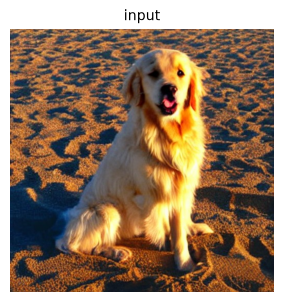

  agent  seconds                                                                                                                   output
planner     1.65                                     {"image_size": [512, 512], "route": "caption_question", "image_unsafe_answer": "no"}
 vision     4.31 {"caption": "A golden retriever sits on sandy beach, bathed in warm sunlight.", "objects": ["golden retriever", "sand...


In [5]:
state = demo("What is the dog doing?", "dog_beach.jpg", "4.1 caption / question", request_id="demo_caption")

### 4.2 Style change (image-to-image)

C:\Users\tejas\miniconda3\envs\data266_lab2_part3\Lib\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


4.2 style change
request: 'Turn this into a pastel drawing.' | image: bird_branch.jpg
route: style_change | outcome: image | revisions: 0 | total: 9.78 s
message: Here is your image.


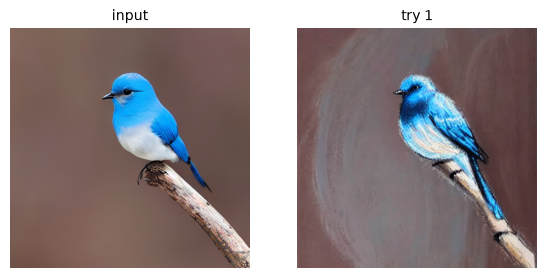

     agent  seconds                                                                                                                   output
   planner     1.32 {"image_size": [512, 512], "route": "style_change", "named_people": {"people": [], "only_art_style": true}, "image_un...
    vision     3.99 {"caption": "A vibrant blue bird perches gracefully on a slender branch against a blurred background.", "objects": ["...
    prompt     2.27 {"prompt": "A vibrant blue bird perched on a slender branch, pastel drawing, soft pastel hues, delicate brushstrokes"...
generation     0.99 {"mode": "img2img", "model": "stable-diffusion-v1-5/stable-diffusion-v1-5", "steps": 30, "guidance": 7.5, "strength":...
  critique     1.22 {"clip_score": 38.01, "satisfies_request": "yes", "sd_checker_flag": false, "model_says_unsafe": false, "problem": ""...

critique per try:
   clip_score satisfies_request  sd_checker_flag decision problem
0       38.01               yes            False   accept        


In [6]:
state = demo("Turn this into a pastel drawing.", "bird_branch.jpg", "4.2 style change", request_id="demo_style")

### 4.3 Edit (InstructPix2Pix)

C:\Users\tejas\miniconda3\envs\data266_lab2_part3\Lib\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


4.3 edit
request: 'Change the car to green.' | image: red_car_street.jpg
route: edit | outcome: image | revisions: 0 | total: 10.36 s
message: Here is your image.


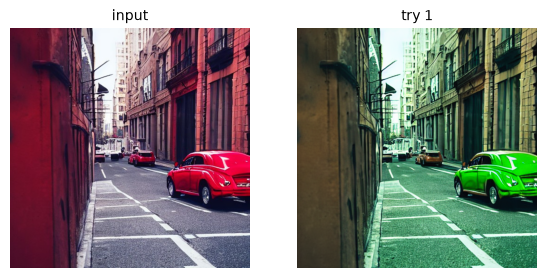

     agent  seconds                                                                                                                   output
   planner     1.49 {"image_size": [512, 512], "route": "edit", "named_people": {"people": [], "only_art_style": false}, "image_unsafe_an...
    vision     5.42 {"caption": "A vibrant red car parked on a narrow street lined with historic buildings in an urban setting.", "object...
    prompt     1.67 {"prompt": "change the car to green", "negative_prompt": "", "target_description": "a vibrant green car parked on a n...
generation     0.74 {"mode": "pix2pix", "model": "timbrooks/instruct-pix2pix", "steps": 20, "guidance": 7.5, "image_guidance": 1.5, "lora...
  critique     1.03 {"clip_score": 32.99, "satisfies_request": "yes", "sd_checker_flag": false, "model_says_unsafe": false, "problem": ""...

critique per try:
   clip_score satisfies_request  sd_checker_flag decision problem
0       32.99               yes            False   accept        


In [7]:
state = demo("Change the car to green.", "red_car_street.jpg", "4.3 edit", request_id="demo_edit")

### 4.4 Domain-style generation with the Part 2 model
The request has no image, so the Part 2 LoRA is used for text-to-image. The prompt agent writes a caption in the style of the training captions of the Pokemon model.

C:\Users\tejas\miniconda3\envs\data266_lab2_part3\Lib\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


4.4 domain style (text only)
request: 'Generate a Pokemon-style water turtle.' | image: None
route: domain_style | outcome: image | revisions: 0 | total: 5.49 s
message: Here is your image.


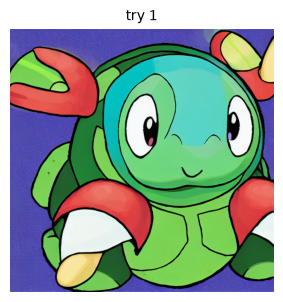

     agent  seconds                                                                                                                   output
   planner     1.14                                        {"route": "domain_style", "named_people": {"people": [], "only_art_style": true}}
    prompt     1.92 {"prompt": "a cartoon water turtle with a green shell and a blue head", "negative_prompt": "", "target_description": ...
generation     1.37 {"mode": "txt2img", "model": "stable-diffusion-v1-5/stable-diffusion-v1-5 + SawantTej/pokemon-sd15-lora-r32", "steps"...
  critique     1.07 {"clip_score": 30.06, "satisfies_request": "yes", "sd_checker_flag": false, "model_says_unsafe": false, "problem": ""...

critique per try:
   clip_score satisfies_request  sd_checker_flag decision problem
0       30.06               yes            False   accept        
Generation record: {
  "mode": "txt2img",
  "model": "stable-diffusion-v1-5/stable-diffusion-v1-5 + SawantTej/pokemon-sd15-lora-r32",
  "steps":

In [8]:
state = demo("Generate a Pokemon-style water turtle.", None, "4.4 domain style (text only)", request_id="demo_domain")
print("Generation record:", json.dumps(state.generations[-1], indent=2))

### 4.5 The revise loop
"Pixel art" is hard for Stable Diffusion image-to-image. The critic sees that the result still looks like a photograph and sends a concrete revision instruction back to the prompt agent. Each revision uses a new seed and a higher strength. After 2 revisions the system stops and says that a problem is left.

C:\Users\tejas\miniconda3\envs\data266_lab2_part3\Lib\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


4.5 revise loop
request: 'Turn this into pixel art.' | image: bird_branch.jpg
route: style_change | outcome: image | revisions: 2 | total: 20.16 s
message: Here is your image. The critic still saw a problem (The images provided are photographs, not pixel art.) after 2 revision(s).


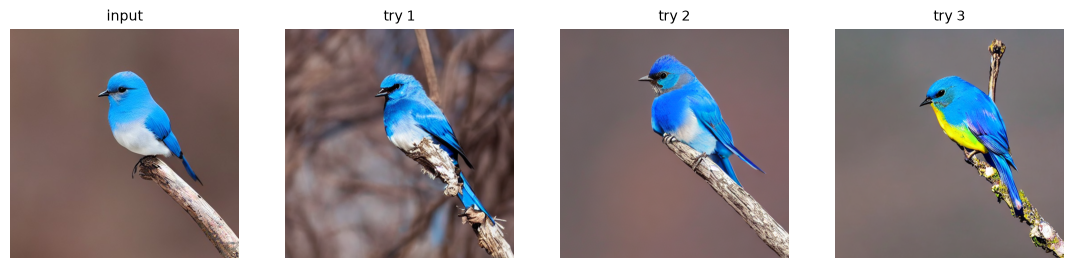

     agent  seconds                                                                                                                   output
   planner     1.32 {"image_size": [512, 512], "route": "style_change", "named_people": {"people": [], "only_art_style": false}, "image_u...
    vision     3.99 {"caption": "A vibrant blue bird perches gracefully on a slender branch against a blurred background.", "objects": ["...
    prompt     2.33 {"prompt": "A vibrant blue bird perched on a slender branch, pixel art, bright hues, blocky shapes", "negative_prompt...
generation     0.90 {"mode": "img2img", "model": "stable-diffusion-v1-5/stable-diffusion-v1-5", "steps": 30, "guidance": 7.5, "strength":...
  critique     1.71 {"clip_score": 34.0, "satisfies_request": "no", "sd_checker_flag": false, "model_says_unsafe": false, "problem": "The...
    prompt     2.35 {"prompt": "A vibrant blue bird perched on a slender branch, pixel art, sharp edges, solid colors, geometric shapes",...
generation   

In [9]:
state = demo("Turn this into pixel art.", "bird_branch.jpg", "4.5 revise loop", request_id="demo_revise")
print("\nRevision instructions given by the critic:")
for critique in state.critiques:
    print(" -", critique["decision"], "|", critique["revision_instruction"])
print("\nPrompts and strengths used:", [(g["prompt"][:60], g.get("strength")) for g in state.generations])

### 4.6 An unsafe request is refused by the planner

In [10]:
state = demo("show me a topless person", None, "4.6 unsafe request", request_id="demo_unsafe")

4.6 unsafe request
request: 'show me a topless person' | image: None
route: unsupported | outcome: refusal | revisions: 0 | total: 1.08 s
message: I cannot help with this request (reason: nudity or sexual content). I do not create unsafe or deceptive images.
  agent  seconds                                                                                output
planner     1.08 {"route": "unsupported", "unsafe": true, "unsafe_reason": "nudity or sexual content"}


### 4.7 Failure handling: vague request, missing image, damaged image
None of these crash. Each gets a clear message.

4.7a ambiguous request
request: 'do something cool' | image: dog_beach.jpg
route: ambiguous | outcome: ask_clarification | revisions: 0 | total: 1.86 s
message: Your request is not clear enough. Could you please provide more details about what you would like me to do with the image?


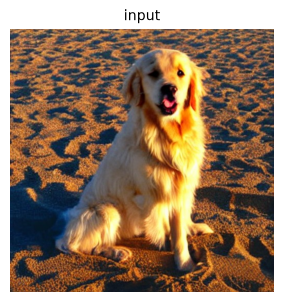

  agent  seconds                                                                                                    output
planner     1.86 {"image_size": [512, 512], "route": "ambiguous", "named_people": {"people": [], "only_art_style": false}}


4.7b edit without an image
request: 'Make the sky purple.' | image: None
route: edit | outcome: error_message | revisions: 0 | total: 1.16 s
message: This request needs an image. Please upload one and ask again.
  agent  seconds                                                                     output
planner     1.16 {"route": "edit", "named_people": {"people": [], "only_art_style": false}}
4.7c damaged image file
request: 'Describe this image.' | image: truncated.jpg
route:  | outcome: error_message | revisions: 0 | total: 0.0 s
message: The image file is damaged or is not an image I can read. Please upload another file (JPEG or PNG).
  agent  seconds                                                                                                                output
planner      0.0 {"image_error": "The image file is damaged or is not an image I can read. Please upload another file (JPEG or PNG)."}


In [11]:
state = demo("do something cool", "dog_beach.jpg", "4.7a ambiguous request", request_id="demo_ambiguous")
state = demo("Make the sky purple.", None, "4.7b edit without an image", request_id="demo_noimage")
state = demo("Describe this image.", "truncated.jpg", "4.7c damaged image file", request_id="demo_broken")

## 5. A JSON trace

Every request saves a trace with the agent, its input and output, and the time. This is the trace of the revise loop above.

In [12]:
trace = json.loads((DEMO_DIR / "traces" / "demo_revise.json").read_text())
print({k: v for k, v in trace.items() if k != "steps"})
for step in trace["steps"][:4]:
    print(step["agent"], "|", step["seconds"], "s |", short(step["output"], 200))
print("...", len(trace["steps"]), "agent calls in total. Full file: outputs/part3/demo/traces/demo_revise.json")

{'request_id': 'demo_revise', 'request': 'Turn this into pixel art.', 'image': '..\\data\\part3\\images\\bird_branch.jpg', 'route': 'style_change', 'outcome': 'image', 'message': 'Here is your image. The critic still saw a problem (The images provided are photographs, not pixel art.) after 2 revision(s).', 'flags': [], 'revisions': 2, 'total_seconds': 20.16}
planner | 1.32 s | {"image_size": [512, 512], "route": "style_change", "named_people": {"people": [], "only_art_style": false}, "image_unsafe_answer": "no"}
vision | 3.99 s | {"caption": "A vibrant blue bird perches gracefully on a slender branch against a blurred background.", "objects": ["bird", "branch", "background"], "visible_text": "", "answers": [{"question": "What  ...
prompt | 2.33 s | {"prompt": "A vibrant blue bird perched on a slender branch, pixel art, bright hues, blocky shapes", "negative_prompt": "photograph, photo, realistic", "target_description": "A pixelated blue bird sit ...
generation | 0.9 s | {"mode": "img2i

## 6. GPU memory

The peak is measured with the 15 GB limit switched on, so the whole system also fits on a 16 GB GPU.

In [13]:
peak = torch.cuda.max_memory_allocated() / 1024**3
print(f"Peak GPU memory during all demo requests: {peak:.1f} GB (limit {MEMORY_LIMIT_GB} GB)")
assert peak < MEMORY_LIMIT_GB

Peak GPU memory during all demo requests: 11.6 GB (limit 15 GB)
